# 02 · Exponential smoothing (ETS) vs the FP&A bar

**What ETS does.** Exponential smoothing keeps a running estimate of three things: the **level** (where revenue is now), the **trend** (how fast it moves) and the **season** (how much each quarter usually sits above or below the level). Each new quarter updates them, giving recent quarters more weight than old ones.

**The three letters** in a model name such as `MAM`:
- **Error:** **A**dditive (misses are about the same in dollars) or **M**ultiplicative (about the same in %).
- **Trend:** **N**one, **A**dditive (grows by a fixed amount per quarter), or **Ad** (additive but damped: growth slowly fades).
- **Season:** **N**one, **A**dditive (Q4 is $X above average) or **M**ultiplicative (Q4 is X % above average).

**AutoETS** tries the sensible combinations and keeps the one with the lowest **AICc**, a score that rewards fitting past quarters but penalises extra parameters. It chooses again at every origin, using only the quarters known then.

**Setup** (the same as Session 1, see CLAUDE.md): rolling origin from 2013 Q1, 65-day rule, first-reported revenue, h = 1–4.

**The bar** = the best baseline per company from Session 1: Mattel B1 (same quarter last year), Caterpillar B0 (last quarter), Alphabet B2 (same quarter last year × growth).

**Main tests, decided before seeing results:** h = 1 and full-year error. Everything else is descriptive.

Code: `src/ets.py`, `src/evaluate_ets.py`.

## Setup

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from baselines import load, FIRST_ORIGIN
from ets import worked_example
from evaluate_ets import (BAR, all_errors, main_tests, coverage, model_choices,
                          leak_check, statsmodels_check)
from evaluate_baselines import metric_table, table_2020

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
first, ets_first = all_errors("revenue_first_reported")     # main run
latest, ets_latest = all_errors("revenue_latest")           # check

## 1. Worked example: Mattel, origin 2013 Q1
The model AutoETS chose, its four forecasts with 80 % intervals, and Session 1's baselines, all in $m.

In [2]:
worked_example(load(), "Mattel", FIRST_ORIGIN)

Mattel, origin 2013Q1: we pretend it is 2013-06-04
Training quarters: 2008Q2 to 2013Q1 (20 quarters)
Model chosen by AICc: MNA  (AICc -29.5)

Forecasts ($m):
  h  target       ETS  80 % interval             B0       B1       B2
  1  2013Q2   1,212.7  1,127.4 – 1,298.0      995.6  1,158.7  1,204.3
  2  2013Q3   2,058.6  1,893.6 – 2,223.6      995.6  2,077.8  2,159.5
  3  2013Q4   2,186.9  1,967.9 – 2,406.0      995.6  2,255.9  2,344.6
  4  2014Q1     963.7    741.5 – 1,185.9      995.6    995.6  1,034.7


## 2. Main tests: ETS vs the bar
For h = 1 and the full year (the sum of the next 4 quarters): MAPE, % improvement over the bar, how often ETS was closer, and the Diebold–Mariano test.

**The Diebold–Mariano (DM) test, in plain words:** for each forecast it takes "ETS's % miss minus the bar's % miss" and asks whether that difference averages zero, which is what you'd expect if the two were equally good. Forecasts from neighbouring origins overlap, so it allows for their misses being linked. The Harvey correction makes it fairer for small samples. A **negative** value means ETS misses less.

**Holm p** corrects for running six main tests (2 tests × 3 companies, Alphabet without Motorola). With six tries, one could come out at p < 0.05 by chance alone.

In [3]:
main_tests(first).round(3)

bar   n  MAPE ETS  MAPE bar  improvement %  \
test      company                                                              
h=1       Mattel                   B1  54      7.49      8.89          15.75   
          Caterpillar              B0  54      5.40      7.22          25.21   
          Alphabet                 B2  54      3.65      5.80          37.19   
          Alphabet excl. Motorola  B2  47      3.41      5.66          39.69   
full year Mattel                   B1  51      6.93      6.36          -9.08   
          Caterpillar              B0  51      9.15      9.23           0.83   
          Alphabet                 B2  51      5.78      6.71          13.91   
          Alphabet excl. Motorola  B2  44      5.88      7.19          18.23   

                                   ETS closer, % of forecasts  DM (HLN)  \
test      company                                                         
h=1       Mattel                                        57.41     -1.16   
          Caterpillar                                   74.07     -2.40   
          Alphabet                                      61.11     -2.60   
          Alphabet excl. Motorola                       61.70     -2.48   
full year Mattel                                        41.18      0.41   
          Caterpillar                                   56.86     -0.17   
          Alphabet                                      39.22     -0.43   
          Alphabet excl. Motorola                       40.91     -0.53   

                                   p-value  Holm p  
test      company                                   
h=1       Mattel                      0.25    1.00  
          Caterpillar                 0.02    0.10  
          Alphabet                    0.01     NaN  
          Alphabet excl. Motorola     0.02    0.10  
full year Mattel                      0.68    1.00  
          Caterpillar                 0.87    1.00  
          Alphabet                    0.67     NaN  
          Alphabet excl. Motorola     0.60    1.00

**What this shows:** one quarter ahead, ETS misses less than every company's bar: Mattel 7.5 % vs 8.9 %, Caterpillar 5.4 % vs 7.2 %, Alphabet 3.4 % vs 5.7 % (without Motorola). The DM test gives p ≈ 0.02 for Caterpillar and Alphabet, but after the Holm correction for six tests both become p = 0.10, so the gains are **suggestive, not proven**. For the **full year**, the number FP&A teams report, ETS is no better than the simple rules (Mattel is even 9 % worse; all p ≥ 0.6).

## 3. MAPE and MASE for every method and horizon (descriptive)

In [4]:
metric_table(first, "ape").round(1)

h=1   h=2   h=3   h=4  full year
company                 baseline                                   
Mattel                  B0       44.70 71.40 41.10  9.40      32.20
                        B1        8.90  9.00  9.10  9.40       6.40
                        B2        8.90  9.80 10.10 11.20       7.70
                        ETS       7.50 10.20 10.60  9.40       6.90
Caterpillar             B0        7.20  8.10 12.20 13.90       9.20
                        B1       14.10 14.00 13.80 13.90      12.30
                        B2       12.00 15.00 17.50 19.70      15.20
                        ETS       5.40  8.40 11.80 13.90       9.20
Alphabet                B0        7.30  9.10 11.70 14.70      10.10
                        B1       15.10 15.50 15.20 14.70      15.10
                        B2        5.80  7.40  8.50  9.10       6.70
                        ETS       3.60  5.60  7.30  8.40       5.80
Alphabet excl. Motorola B0        7.50  9.20 11.90 15.20      10.40
                        B1       15.20 15.20 15.20 15.20      15.20
                        B2        5.70  7.10  8.20  8.80       7.20
                        ETS       3.40  5.50  7.20  8.80       5.90

In [5]:
metric_table(first, "ase").round(2)

h=1  h=2  h=3  h=4
company                 baseline                    
Mattel                  B0       4.94 8.50 5.12 1.19
                        B1       1.12 1.15 1.15 1.19
                        B2       1.16 1.24 1.26 1.42
                        ETS      0.98 1.28 1.31 1.20
Caterpillar             B0       0.39 0.44 0.64 0.73
                        B1       0.74 0.74 0.74 0.73
                        B2       0.63 0.79 0.93 1.05
                        ETS      0.29 0.45 0.62 0.73
Alphabet                B0       1.04 1.34 1.81 2.33
                        B1       2.11 2.24 2.29 2.33
                        B2       0.82 1.07 1.28 1.41
                        ETS      0.50 0.81 1.11 1.35
Alphabet excl. Motorola B0       1.12 1.41 1.90 2.45
                        B1       2.24 2.32 2.39 2.45
                        B2       0.85 1.10 1.31 1.44
                        ETS      0.51 0.84 1.15 1.43

**What this shows:** ETS's lead is largest at h = 1 and fades with the horizon. By h = 4 it ties the bar everywhere (Mattel 9.5 vs 9.4 %, Caterpillar 13.9 vs 13.9 %, Alphabet 8.8 vs 8.8 %). At h = 2–3, Mattel's ETS is even worse than B1. MASE tells the same story: below 1 at h = 1 for all three companies, at or above 1 for Mattel and Alphabet by h = 3–4.

## 4. Are the 80 % intervals honest?
The share of actuals that fell inside ETS's 80 % prediction interval. It should be about 80 %. Lower means the intervals are too narrow (overconfident); higher means too wide.

In [6]:
coverage(ets_first).round(1)

,h=1,h=2,h=3,h=4,all h
company,,,,,
Mattel,74.10,69.80,78.80,80.40,75.70
Caterpillar,87.00,81.10,75.00,72.50,79.00
Alphabet,77.80,69.80,88.50,94.10,82.40
Alphabet excl. Motorola,78.70,66.00,87.20,93.60,81.40


**What this shows:** over all horizons, the actual fell inside the 80 % interval 76–81 % of the time, which is about right on average. But it's uneven: at h = 2 the bands are too narrow (66–81 %), and for Alphabet at h = 4 too wide (94 %). So the intervals are a reasonable rough guide, not a precise risk measure.

## 5. Which models did AutoETS pick?
One choice per origin (54 per company), and how often it switched between consecutive origins.

In [7]:
model_choices(ets_first)

model,MAN,MAM,ANN,ANA,MNA,MNM,MAA,switches,origins
company,,,,,,,,,
Alphabet,5,49,0,0,0,0,0,1,54
Caterpillar,0,0,5,49,0,0,0,1,54
Mattel,0,0,0,0,16,36,2,4,54


**What this shows:** AutoETS hardly ever changed its mind. Alphabet was MAM at 49 of 54 origins (multiplicative error, additive trend, multiplicative season); Caterpillar ANA at 49 (no trend: level plus additive season); Mattel MNM at 36 and MNA at 16 (no trend, seasonal). It switched only 1, 1 and 4 times. Caterpillar's "no trend" choice explains why ETS beats B0 there: it's B0 plus a small seasonal adjustment, with the level smoothed over recent quarters.

## 6. The year 2020
MAPE for targets in 2020 vs all other years (Alphabet without Motorola).

In [8]:
table_2020(first).round(1)

h=1             all h            
targets                           2020 other years  2020 other years
company                 baseline                                    
Mattel                  B0       55.60       43.90 54.00       41.00
                        B1       13.00        8.60 13.00        8.80
                        B2       14.20        8.50 12.50        9.80
                        ETS       7.80        7.50 12.30        9.20
Caterpillar             B0       10.80        6.90 20.80        9.40
                        B1       29.30       12.90 29.30       12.70
                        B2       18.10       11.50 27.40       15.00
                        ETS       9.50        5.10 19.60        9.00
Alphabet excl. Motorola B0       13.80        6.90 12.80       10.80
                        B1       11.20       15.60 11.20       15.60
                        B2        9.00        5.40  9.20        7.30
                        ETS       9.90        2.80  9.00        6.00

**What this shows:** Mattel's ETS hardly noticed 2020 (7.8 % vs 7.5 % in other years at h = 1), while B1 jumped to 13 %. Caterpillar's ETS roughly doubled (9.5 vs 5.1 %) but stayed better than its bar B0 (10.8 %). Alphabet's ETS more than tripled (9.9 vs 2.8 %) and was slightly worse than B2 (9.0 %), because it extrapolated growth into the 2020 Q2 dip and then lagged the rebound.

## 7. Checks before trusting the result
1. **First-reported vs latest revenue:** does the result depend on restatements?
2. **Leaks:** was every training quarter really public at the origin?
3. **Another library:** refit the same model in statsmodels at every origin. If the result came from one optimiser's quirks, the two would differ.

In [9]:
chk = pd.concat({"first reported": metric_table(first, "ape"), "latest": metric_table(latest, "ape")}, axis=1)
chk.loc[(slice(None), "ETS"), [(s, c) for c in ["h=1", "full year"] for s in ["first reported", "latest"]]].round(2)

,,first reported,latest,first reported,latest
,,h=1,h=1,full year,full year
company,baseline,,,,
Mattel,ETS,7.49,7.48,6.93,6.92
Caterpillar,ETS,5.40,5.40,9.15,9.15
Alphabet,ETS,3.64,3.27,5.78,5.63
Alphabet excl. Motorola,ETS,3.41,3.30,5.88,5.85


In [10]:
leak_check(ets_first, load())

forecast rows                                   630
training ends after the origin                    0
last training quarter filed after the cutoff      0
target not after the training data                0
dtype: int64

In [11]:
statsmodels_check(ets_first, load()).round(2)

,"MAPE h=1, statsforecast","MAPE h=1, statsmodels (same model)"
company,,
Mattel,7.49,7.07
Caterpillar,5.40,5.38
Alphabet,3.64,3.69
Alphabet excl. Motorola,3.41,3.48


**What this shows:** (1) using restated instead of first-reported revenue changes ETS's MAPE by at most 0.4 points. (2) No leaks: in all 630 forecasts, the training data ended at or before the origin and was public by the cutoff. (3) Refitting the same models in statsmodels gives nearly the same MAPE (Mattel 7.1 vs 7.5 %, Caterpillar 5.4 vs 5.4 %, Alphabet 3.5 vs 3.4 %), so the result doesn't come from one library's optimiser.

## 8. Actual vs ETS vs the bar, one quarter ahead
Solid: first-reported revenue. Dashed with a shaded band: ETS and its 80 % interval. Dotted: the company's bar. The grey band marks 2020; for Alphabet, a lighter band marks the Motorola targets.

In [12]:
ACTUAL, ETSC, BARC = "#2a78d6", "#eb6834", "#1baf7a"      # default palette slots 1-3
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e1e0d9", "#f0efec"
BAR_NAME = {"B0": "B0 last quarter", "B1": "B1 same quarter last year", "B2": "B2 same quarter × growth"}

def chart(company):
    e = ets_first[(ets_first["company"] == company) & (ets_first["h"] == 1)].set_index("target")
    bar = BAR[company]
    b = first[(first["company"] == company) & (first["h"] == 1) & (first["baseline"] == bar)].set_index("target")
    x = e.index.to_timestamp(how="end")
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2020-12-31"), color=BAND, zorder=0)
    ax.text(pd.Timestamp("2020-07-01"), 0.97, "2020", transform=ax.get_xaxis_transform(),
            color=MUTED, fontsize=9, va="top", ha="center")
    if company == "Alphabet":
        ax.axvspan(x.min(), pd.Timestamp("2014-12-31"), color=BAND, alpha=0.6, zorder=0)
        ax.text(pd.Timestamp("2013-06-30"), 0.97, "Motorola", transform=ax.get_xaxis_transform(),
                color=MUTED, fontsize=9, va="top")
    ax.fill_between(x, e["lo80"] / 1e9, e["hi80"] / 1e9, color=ETSC, alpha=0.15, lw=0,
                    label="ETS 80 % interval")
    ax.plot(x, e["actual"] / 1e9, color=ACTUAL, lw=2, label="Actual (first reported)")
    ax.plot(x, e["ets"] / 1e9, color=ETSC, lw=1.6, ls="--", label="ETS")
    ax.plot(x, b["forecast"] / 1e9, color=BARC, lw=1.6, ls=":", label=f"Bar: {BAR_NAME[bar]}")
    m_ets = first[(first["company"] == company) & (first["h"] == 1) & (first["baseline"] == "ETS")]["ape"].mean()
    ax.set_title(f"{company}: one quarter ahead   (MAPE ETS {m_ets:.1f} %, {bar} {b['ape'].mean():.1f} %)",
                 loc="left", color=INK, fontsize=12)
    ax.set_ylabel("Revenue, $bn", color=MUTED)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=4, labelcolor=MUTED)
    fig.tight_layout()
    plt.show()

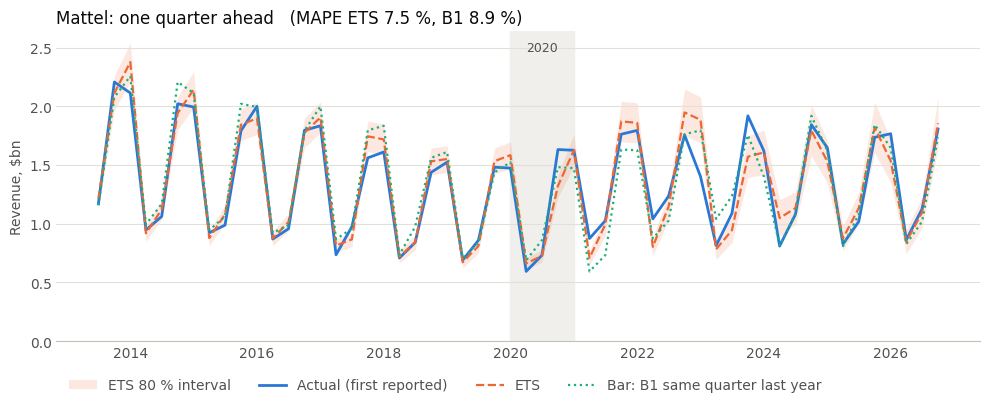

In [13]:
chart("Mattel")

**What this shows:** ETS (dashed) follows Mattel's seasonal saw-tooth closely, a little more smoothly than B1 (dotted). Its biggest misses are the same pattern-breaking quarters that hurt the baselines: the weak 2022 Q4 (+34 %) and 2024 Q1 (+30 %). The narrow band (about ±7.5 %) missed 14 of 54 quarters, mostly in 2017 and 2020–2024.

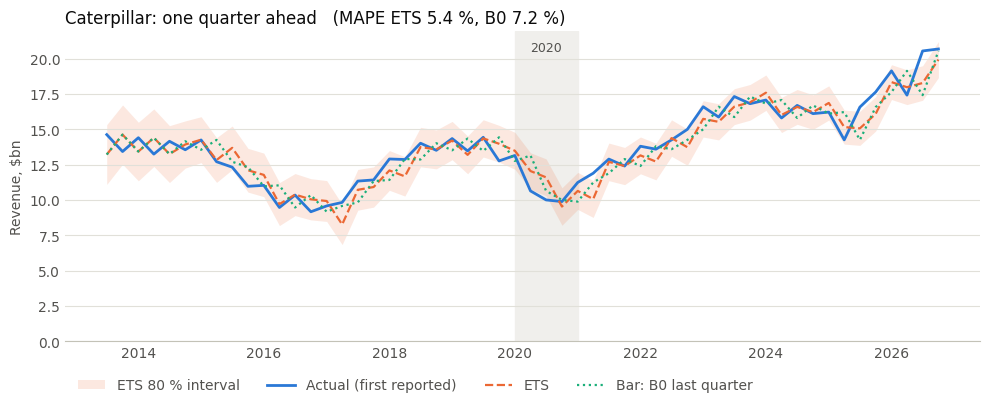

In [14]:
chart("Caterpillar")

**What this shows:** ETS tracks the cycle almost like B0 (last quarter), but adds Caterpillar's small seasonal pattern and smooths out noise. That's why it misses less, especially in calm stretches like 2017–2019 and 2023–2024. At the sharp turns (2020 Q2 +16 %, 2021 Q1 −15 %) it's caught out like everyone, and those are most of the 7 quarters outside its band.

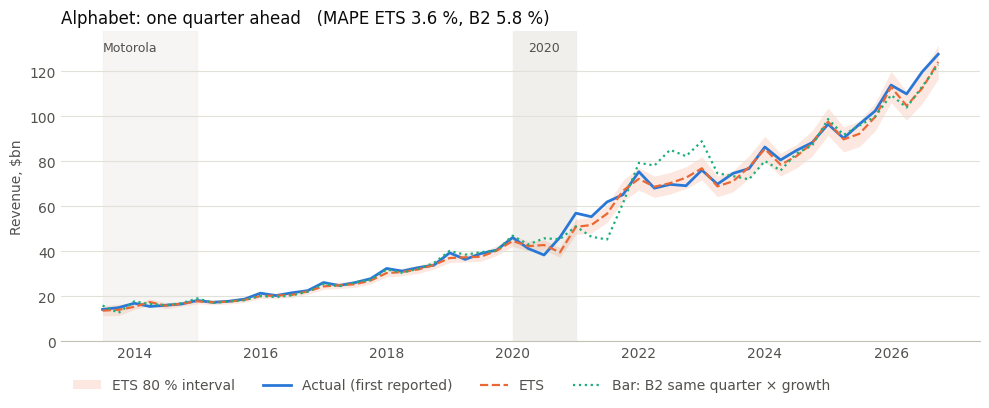

In [15]:
chart("Alphabet")

**What this shows:** ETS hugs the actual line and avoids B2's 2022 overshoot (dotted line, up to 22 % too high), because it updates the trend every quarter instead of using a whole year's growth. It leans slightly low (it over-forecasts only 28 % of the time) and its band misses several holiday Q4s (2015–2018) and the 2020–2021 swings.

## Summary

| Company | Bar | MAPE h = 1: ETS vs bar | DM p (Holm) | Full year: ETS vs bar |
|---|---|---|---|---|
| Mattel | B1 | 7.5 % vs 8.9 % | 0.25 (1.00) | 6.9 % vs 6.4 % (worse) |
| Caterpillar | B0 | 5.4 % vs 7.2 % | 0.02 (0.10) | 9.2 % vs 9.2 % (same) |
| Alphabet excl. Motorola | B2 | 3.4 % vs 5.7 % | 0.02 (0.10) | 5.9 % vs 7.2 % (n.s.) |

**Plainly:** ETS is a better *next-quarter* forecaster than the best simple rule for every company (16–40 % smaller misses). The evidence is suggestive, not conclusive after correcting for six tests. For the *full-year* number it adds nothing over the simple rules, and its lead disappears by four quarters ahead. The new bar for the next sessions: ETS at h = 1, the best baseline for the full year.